# Predicción de Churn (cancelación de clientes) — Telco

**Objetivo de negocio:** una empresa de telecomunicaciones pierde ingresos cada vez que
un cliente cancela su servicio (*churn*). Retener a un cliente existente cuesta entre
5 y 25 veces menos que adquirir uno nuevo, así que anticipar **quién está en riesgo de
irse** permite a la empresa actuar antes (ofertas, llamadas de retención, etc.).

**Pregunta de ciencia de datos:** dado el perfil de un cliente (servicios contratados,
forma de pago, antigüedad, cargos mensuales), ¿podemos predecir si va a cancelar?

**Dataset:** 7,043 clientes de una telco (dataset público de IBM), 21 variables:
demográficas, servicios contratados y variable objetivo `Churn` (Yes/No).

Este notebook cubre: carga y limpieza de datos, análisis exploratorio (EDA),
preparación de features, y un modelo baseline de clasificación con evaluación
honesta (no solo accuracy, que engaña en problemas desbalanceados).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

df = pd.read_csv("../data/telco_churn.csv")
print(df.shape)
df.head()


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Estructura y tipos de datos

Antes de analizar nada, hay que entender qué tiene el dataset: cuántas filas, qué tipo
de dato tiene cada columna, y si hay valores nulos evidentes.


In [2]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 2. Limpieza: el problema de `TotalCharges`

`TotalCharges` aparece como tipo `object` (texto) en vez de numérico. Esto casi siempre
significa que hay valores no numéricos escondidos (espacios en blanco, strings vacíos).
Vamos a encontrarlos antes de convertir, en vez de forzar la conversión y perder el
rastro del problema.


In [3]:
# pd.to_numeric con errors='coerce' convierte lo que no es número en NaN,
# así podemos ver cuántos registros tienen el problema
total_charges_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
problematic = df[total_charges_numeric.isna()]
print(f"Registros problemáticos: {len(problematic)}")
problematic[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]


Registros problemáticos: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


Los 11 casos problemáticos tienen `tenure` (antigüedad) = 0: son clientes **nuevos**
que todavía no han sido facturados, por eso `TotalCharges` viene vacío. No es un error
de carga de datos, es un comportamiento esperado del negocio.

Decisión: convertimos la columna a numérico y rellenamos esos 11 casos con 0
(no han acumulado cargos todavía), en vez de eliminarlos — perderíamos información
de clientes nuevos, que son justamente un segmento relevante para churn.


In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# customerID no aporta a la predicción (es un identificador único por fila)
df = df.drop(columns=["customerID"])

df["TotalCharges"].describe()


count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64

## 3. Variable objetivo: ¿qué tan desbalanceado está el problema?

Esto es clave: si el 95% de los clientes NO cancela, un modelo que siempre prediga
"No cancela" tendría 95% de accuracy sin aprender nada útil. Por eso hay que mirar
el balance de clases *antes* de elegir métricas de evaluación.


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


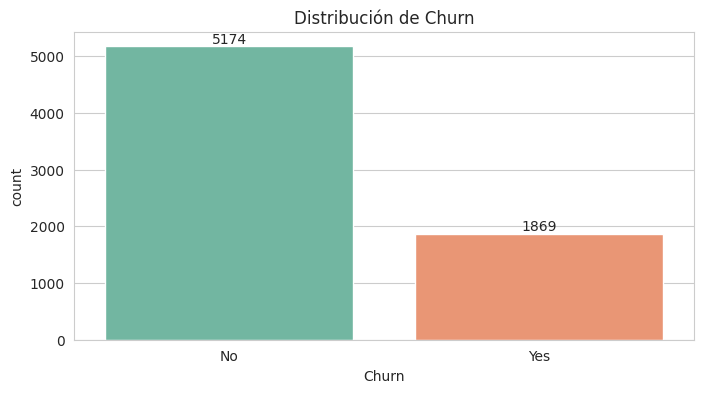

In [5]:
churn_counts = df["Churn"].value_counts(normalize=True) * 100
print(churn_counts)

ax = sns.countplot(data=df, x="Churn", hue="Churn", palette="Set2", legend=False)
ax.set_title("Distribución de Churn")
for container in ax.containers:
    ax.bar_label(container)
plt.show()


~26.5% de los clientes cancela. No es un desbalance extremo (como fraude, donde el
positivo puede ser <1%), pero sí lo suficiente como para que **accuracy sola sea
engañosa**. Vamos a priorizar *recall* y *F1* de la clase "Yes" más adelante: para el
negocio, es peor no detectar a alguien que se va a ir (falso negativo) que gastar un
poco de esfuerzo de retención en alguien que de todos modos se iba a quedar (falso
positivo).


## 4. ¿Qué variables se relacionan con churn?

Exploramos tres variables con hipótesis de negocio clara antes de graficar:
- **Contract**: ¿los clientes mes a mes cancelan más que los de contrato anual? (hipótesis: sí, menos compromiso)
- **tenure**: ¿los clientes nuevos cancelan más que los antiguos?
- **MonthlyCharges**: ¿pagar más se relaciona con cancelar más?


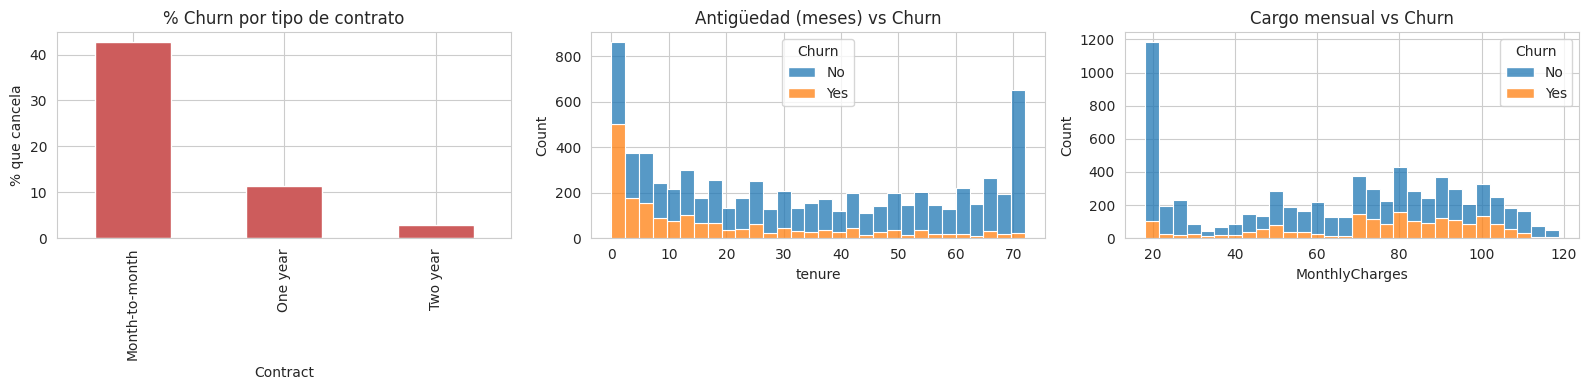

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
contract_churn["Yes"].plot(kind="bar", ax=axes[0], color="indianred")
axes[0].set_title("% Churn por tipo de contrato")
axes[0].set_ylabel("% que cancela")

sns.histplot(data=df, x="tenure", hue="Churn", multiple="stack", ax=axes[1], bins=30)
axes[1].set_title("Antigüedad (meses) vs Churn")

sns.histplot(data=df, x="MonthlyCharges", hue="Churn", multiple="stack", ax=axes[2], bins=30)
axes[2].set_title("Cargo mensual vs Churn")

plt.tight_layout()
plt.show()


**Lecturas de negocio:**
- Contrato mes a mes tiene una tasa de cancelación muchísimo más alta que los contratos
  de 1 o 2 años: confirma la hipótesis de que el compromiso contractual retiene.
- La mayoría de las cancelaciones ocurren en los primeros meses (tenure bajo): el riesgo
  es más alto justo al inicio de la relación con el cliente.
- Cargos mensuales más altos se asocian a más cancelación — posible sensibilidad al precio.

Estas tres observaciones ya son, por sí solas, insumos accionables para el negocio
(ej. foco de retención en los primeros 3 meses, incentivos a contratos largos).


## 5. Preparación de features para el modelo

- Variables categóricas → one-hot encoding (`pd.get_dummies`).
- Variable objetivo `Churn` → 0/1.
- Split 80/20 en train/test, **estratificado** por la variable objetivo para que el
  desbalance de clases se mantenga igual en ambos conjuntos.


In [7]:
from sklearn.model_selection import train_test_split

y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["Churn"])
X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Tasa de churn train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")


Train: (5634, 30), Test: (1409, 30)
Tasa de churn train: 0.265, test: 0.265


## 6. Modelo baseline: Regresión Logística

Empezamos con un modelo simple e interpretable, no con el más complejo. Es la práctica
correcta: primero establecer una línea base honesta, después comparar modelos más
sofisticados contra ella (eso lo dejamos para la fase 2).

Usamos `class_weight="balanced"` para que el modelo no ignore la clase minoritaria
por el desbalance que vimos en el punto 3.


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]


## 7. Evaluación: más allá del accuracy

Reportamos accuracy solo como referencia, pero las métricas que importan de verdad acá
son **recall** (¿qué % de los que realmente cancelan detectamos?), **precision** y
**ROC-AUC** (¿qué tan bien separa el modelo ambas clases en general?).


              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.841


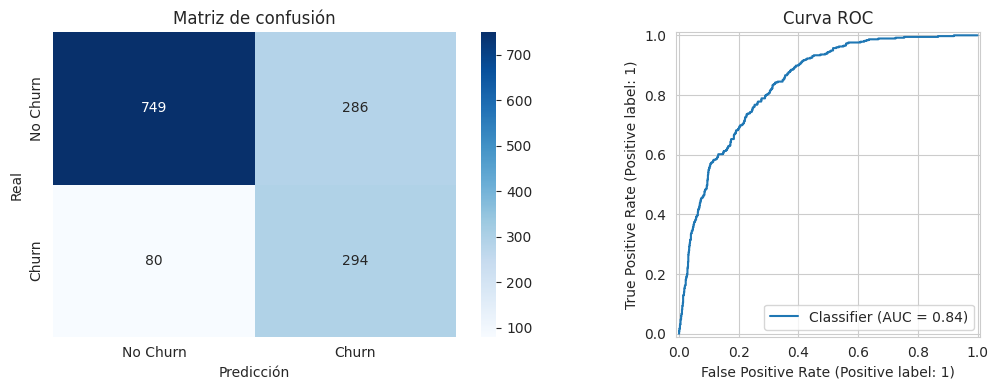

In [9]:
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay
)

print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"], ax=axes[0])
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Real")
axes[0].set_title("Matriz de confusión")

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title("Curva ROC")

plt.tight_layout()
plt.show()


## 8. Conclusiones y próximos pasos

**Resultado baseline:** la regresión logística logra separar razonablemente bien ambas
clases (ver ROC-AUC arriba), con un recall útil para la clase Churn gracias al balanceo
de clases — es decir, el modelo sí está detectando una porción real de los clientes que
se van, no solo prediciendo la clase mayoritaria.

**Insights de negocio del EDA:**
1. El riesgo de churn es más alto en contratos mes a mes.
2. Los primeros meses de vida del cliente concentran la mayoría de las cancelaciones.
3. Cargos mensuales altos se asocian a más cancelación.

**Próximos pasos (fase 2):**
- Comparar contra Random Forest / Gradient Boosting.
- Interpretabilidad con SHAP: ¿qué variables pesan más para *cada* cliente, no solo en
  promedio?
- Ajustar el umbral de decisión según el costo real de negocio (falso negativo vs.
  falso positivo).
- Dashboard interactivo en Streamlit para explorar predicciones por cliente.
